# 03 One-stage anchor-based detector: RetinaNet
Logic lives in `hw2.analysis` (`runs`, `anchors`, `failures`); this notebook only reads saved results from `results/` and figures from `images/`.

In [1]:
import pandas as pd

from hw2.analysis import runs

pd.set_option("display.precision", 4, "display.max_columns", 30, "display.width", 200)

## 1. Faster R-CNN and RetinaNet runs
Val (all original frames, ignore regions, 500 boxes) and val_testlike metrics from `results/F*.json` and `results/R*.json`; LB from `results/lb_scores.csv`.

In [2]:
runs.results_table()

,name,mAP,AP50,AP75,APs,APm,APl,AR500,testlike mAP,testlike APs,train h,epochs,ms/img,LB
exp,,,,,,,,,,,,,,
F0,F0_frcnn_base,0.2080,0.4269,0.1774,0.1014,0.2002,0.3744,0.4218,0.1941,0.1270,2.4288,9.42,267.2010,None
F1,F1_frcnn_anchors16,0.2076,0.4387,0.1689,0.0895,0.1928,0.3839,0.4151,0.1975,0.1286,2.4325,9.32,257.2498,None
R0,R0_retina_base,0.1788,0.3476,0.1608,0.0655,0.1608,0.3363,0.3503,0.1678,0.0958,2.4727,11.54,213.4542,None
R1,R1_retina_kmeans,0.1685,0.3624,0.1312,0.0644,0.1543,0.3056,0.3935,0.1566,0.1029,2.4835,11.36,211.6750,None


Observation: TODO

## 2. Training curves (R0 vs R1)

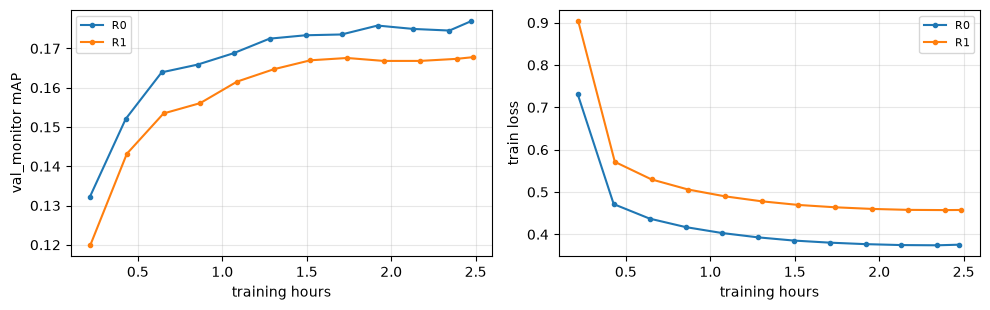

In [3]:
runs.plot_curves(["R0", "R1"]);

Observation: TODO

## 3. k-means anchors on train boxes
IoU-distance k-means (k = 9, seed 42) on train box shapes rescaled to the model input; ratios are h/w as torchvision uses them.

In [4]:
kmeans = runs.load_analysis("anchors")["kmeans"]
anchors = pd.DataFrame(kmeans["anchors_wh"], columns=["w", "h"]).assign(h_over_w=lambda d: d.h / d.w)
print(f"mean best IoU {kmeans['mean_best_iou']:.3f} | ratios {kmeans['ratios_h_over_w']} vs {kmeans['default_ratios']} | differ {kmeans['ratios_differ']}")
anchors.round(2)

mean best IoU 0.726 | ratios [0.61, 1.09, 1.63] vs [0.5, 1.0, 2.0] | differ False


,w,h,h_over_w
0,11.4,15.7,1.38
1,15.2,28.9,1.90
2,24.9,19.5,0.78
3,22.9,37.0,1.62
4,42.4,27.6,0.65
5,34.3,48.4,1.41
6,74.8,39.0,0.52
7,55.8,67.9,1.22
8,118.6,78.7,0.66


Observation: TODO

## 4. Anchor coverage: default (32-512) vs 16-256
Share of train boxes (%, 500 frames) whose best anchor IoU at model input reaches 0.5 (RetinaNet foreground) / 0.4 (background edge).

![anchor coverage](../images/anchor_coverage.png)

In [5]:
runs.coverage_table("retinanet").round(1)

iou>=0.5                    iou>=0.4                    
bucket     small medium large   all    small medium  large   all
anchors                                                         
16-256      82.6   99.4  99.2  95.1     92.0  100.0  100.0  98.0
default     19.7   87.3  99.9  71.8     33.0   93.6  100.0  79.1

Observation: TODO

## 5. TIDE error breakdown (R0)

![R0 TIDE](../images/R0_tide.png)

In [6]:
r0 = runs.load_analysis("R0_failures")
pd.Series({**r0["tide"]["main"], **r0["tide"]["special"]}, name="dAP50").round(2).to_frame().T

,Cls,Loc,Both,Dupe,Bkg,Miss,FalsePos,FalseNeg
dAP50,16.34,4.67,0.45,0.09,1.58,12.16,24.82,24.92


Observation: TODO

## 6. Failure gallery (R0)
Frames with the most missed small objects, class confusions and duplicates; GT green, predictions with score >= 0.3 red.

![R0 fail 1](../images/R0_fail_1.png)
![R0 fail 2](../images/R0_fail_2.png)
![R0 fail 3](../images/R0_fail_3.png)

In [7]:
pd.DataFrame(r0["gallery"]).set_index("n")

,kind,frame,missed_small,confusions,duplicates
n,,,,,
1,missed_small,uav0000182_00000_v/0000190,25,23,0
2,confusions,uav0000182_00000_v/0000212,17,33,2
3,duplicates,uav0000086_00000_v/0000144,4,1,7


Observation: TODO